# Sesión 2 · Lab: el significado como geometría
**Herramientas para el Procesamiento de Lenguaje Natural**

En la sesión 1 convertimos texto en conteos con la bolsa de palabras. Hoy damos tres pasos más: pesar las palabras (**TF-IDF**), descubrir temas ocultos (**LSA** y **LDA**) y aprender vectores que capturan significado (**Word2Vec** y **FastText**). Al final construimos **BPE** desde cero y dibujamos la red de personajes del Quijote.

---
## Parte 0 · Corpus y preparación

In [1]:
import importlib, subprocess, sys
if importlib.util.find_spec("gensim") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim"], check=False)

import re, math, random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

rng = np.random.default_rng(42)
print("Listo ✔")

Listo ✔


In [2]:
LIBROS = {"Cervantes": 2000, "Galdós": 17340, "Pardo Bazán": 18005, "Quiroga": 13507}
COLORES = {"Cervantes": "#14B8A6", "Galdós": "#FFB020", "Pardo Bazán": "#FF6B6B", "Quiroga": "#6C4FF6"}
CARPETA = Path("corpus"); CARPETA.mkdir(exist_ok=True)

def quitar_encabezado_gutenberg(t):
    a = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", t, re.I | re.S)
    b = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK", t, re.I)
    return t[(a.end() if a else 0):(b.start() if b else len(t))].strip()

def descargar_libro(i):
    f = CARPETA / f"pg{i}.txt"
    if not f.exists():
        for url in [f"https://www.gutenberg.org/cache/epub/{i}/pg{i}.txt", f"https://www.gutenberg.org/files/{i}/{i}-0.txt"]:
            try:
                r = requests.get(url, timeout=30)
                if r.status_code == 200:
                    f.write_bytes(r.content); break
            except requests.RequestException:
                pass
        else:
            raise RuntimeError(f"No pude descargar {i}. Sube corpus/pg{i}.txt a mano.")
    return quitar_encabezado_gutenberg(f.read_bytes().decode("utf-8", errors="replace"))

textos = {a: descargar_libro(i) for a, i in LIBROS.items()}

def tokens_de(texto):
    return re.findall(r"[a-záéíóúüñ]+", texto.lower())

def oraciones_de(texto):
    return [tokens_de(o) for o in re.split(r"[.!?;:]+", texto) if len(tokens_de(o)) > 2]

tokens = {a: tokens_de(t) for a, t in textos.items()}

def fragmentar(toks, n=500, maximo=80):
    frs = [toks[i:i + n] for i in range(0, len(toks) - n + 1, n)]
    rng.shuffle(frs)
    return frs[:maximo]

fragmentos, autores = [], []
for a, toks in tokens.items():
    for f in fragmentar(toks):
        fragmentos.append(f); autores.append(a)
autores = np.array(autores)

print(pd.Series(autores).value_counts().rename("fragmentos de 500 palabras"))

Cervantes      80
Galdós         80
Pardo Bazán    80
Quiroga        80
Name: fragmentos de 500 palabras, dtype: int64


---
## Parte 1 · TF-IDF desde cero

La bolsa de palabras le da el mismo peso a *de* que a *escudero*. TF-IDF corrige eso:

$$\text{tf-idf}(t, d) = \underbrace{\frac{\text{veces que } t \text{ aparece en } d}{\text{palabras en } d}}_{\text{TF: qué tanto la usa este documento}} \times \underbrace{\log \frac{N}{\text{documentos que contienen } t}}_{\text{IDF: qué tan rara es en la colección}}$$

Una palabra pesa mucho si aparece **mucho en este documento** y **poco en los demás**.

In [3]:
def tfidf_desde_cero(docs, min_df=2):
    N = len(docs)
    df = Counter(t for d in docs for t in set(d))
    vocab = sorted(t for t, c in df.items() if c >= min_df)
    idx = {t: j for j, t in enumerate(vocab)}
    idf = np.array([math.log(N / df[t]) for t in vocab])
    X = np.zeros((N, len(vocab)))
    for i, d in enumerate(docs):
        conteo = Counter(t for t in d if t in idx)
        for t, c in conteo.items():
            X[i, idx[t]] = c / len(d)
    return X * idf, vocab, idf

X_tfidf, vocab, idf = tfidf_desde_cero(fragmentos)
print(f"Matriz TF-IDF: {X_tfidf.shape[0]} fragmentos × {X_tfidf.shape[1]:,} palabras")
print(f"Celdas en cero: {1 - np.count_nonzero(X_tfidf) / X_tfidf.size:.1%}")

serie_idf = pd.Series(idf, index=vocab).sort_values()
print("\nIDF más bajo (aparecen en casi todos los fragmentos):", list(serie_idf.index[:12]))
print("IDF más alto (aparecen en solo dos fragmentos):", list(serie_idf.index[-12:]))

Matriz TF-IDF: 320 fragmentos × 8,450 palabras
Celdas en cero: 97.3%

IDF más bajo (aparecen en casi todos los fragmentos): ['a', 'y', 'de', 'se', 'el', 'la', 'que', 'en', 'con', 'no', 'los', 'por']
IDF más alto (aparecen en solo dos fragmentos): ['enviase', 'envilecido', 'envite', 'entreabrió', 'entrecerrando', 'entrecortada', 'entrecortados', 'entregadas', 'aborreces', 'aborrecerla', 'órbitas', 'órganos']


In [4]:
# Comparación con scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(analyzer=lambda d: d, min_df=2)
X_sk = vec.fit_transform(fragmentos)
# scikit-learn suaviza el IDF (log((1+N)/(1+df)) + 1) y normaliza cada fila; por eso los números pueden no ser idénticos
print("Vocabulario de scikit-learn:", X_sk.shape[1], "palabras")

Vocabulario de scikit-learn: 8450 palabras


In [5]:
# Palabras más características de cada autor: TF-IDF promedio de sus fragmentos
for a in LIBROS:
    prom = X_tfidf[autores == a].mean(axis=0)
    top = np.argsort(prom)[::-1][:15]
    print(f"{a:12s}", ", ".join(vocab[j] for j in top))

Cervantes    quijote, sancho, don, merced, vuestra, respondió, caballero, lotario, camila, yo, señor, mi, dijo, os, me
Galdós       nela, florentina, teodoro, tú, te, golfín, d, ciego, sofía, me, usted, pablo, tu, yo, celipín
Pardo Bazán  julián, nucha, usted, perucho, pedro, marqués, primitivo, señorito, don, ulloa, barbacana, eugenio, capellán, pazos, arcipreste
Quiroga      nébel, maría, lidia, fué, mamá, perros, cayé, caballos, podeley, noche, amor, aún, mi, monte, me


💬 ¿Qué tipo de palabras aparecen arriba?

---
## Parte 2 · Similitud coseno: buscar fragmentos parecidos

Dos documentos se parecen si sus vectores **apuntan en la misma dirección**, sin importar su largo:

$$\cos(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\| \, \|\vec{b}\|}$$

In [6]:
def normalizar_filas(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)

Xn = normalizar_filas(X_tfidf)
consulta = rng.integers(len(fragmentos))
sim = Xn @ Xn[consulta]
orden = np.argsort(sim)[::-1][1:6]

print(f"Fragmento de consulta ({autores[consulta]}):\n  {' '.join(fragmentos[consulta][:40])}…\n")
for j in orden:
    print(f"  similitud {sim[j]:.2f} · {autores[j]:12s} · {' '.join(fragmentos[j][:15])}…")

Fragmento de consulta (Cervantes):
  yo desde aquí adelante creeré y haré creer a todos los de mi casa y aun al duque mi señor si fuere menester que hay dulcinea en el toboso y que vive hoy día y es hermosa y principalmente nacida…

  similitud 0.19 · Cervantes    · muchas veces y aun agora la tengo sácame deste peligro que no anda todo limpio…
  similitud 0.17 · Cervantes    · alguno pues lo primero que digo dijo es que el vulgo tiene a vuestra merced…
  similitud 0.16 · Cervantes    · si lo son comunicaré con ellos mis desgracias y si no no hay para qué…
  similitud 0.16 · Cervantes    · es fácil a los encantadores tomar la figura que se les antoja y habrán tomado…
  similitud 0.15 · Cervantes    · con su paño de cabeza y candil en la mano y con una muy mala…


---
## Parte 3 · LSA: temas latentes con SVD

La matriz TF-IDF tiene miles de columnas casi vacías. La **descomposición en valores singulares** (SVD) la comprime en unas cuantas dimensiones que agrupan palabras que suelen aparecer juntas. A eso se le llama **Latent Semantic Analysis** (Deerwester et al., 1990).

$$X \approx U_k \, \Sigma_k \, V_k^\top$$

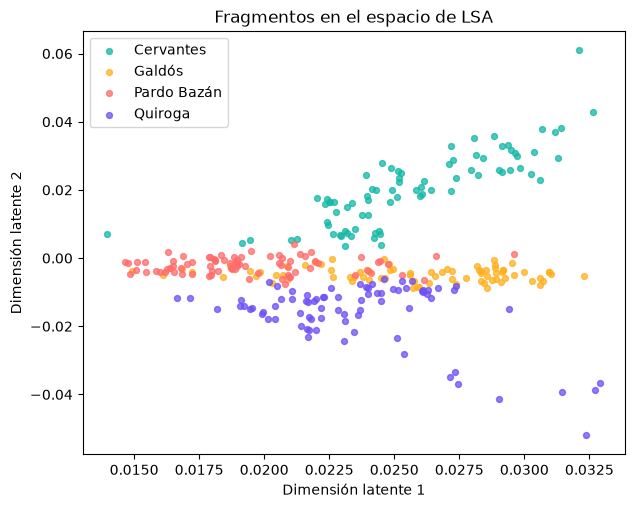

Tema latente 1: quijote, don, nela, sancho, me, usted, te, mi, nébel, yo
Tema latente 2: quijote, sancho, don, vuestra, merced, caballero, respondió, señor, mancha, dulcinea
Tema latente 3: nébel, quijote, lidia, caballos, sancho, toro, don, alazán, malacara, alambrado
Tema latente 4: nébel, lidia, octavio, morfina, madre, quijote, ramo, sancho, concordia, arrizabalaga
Tema latente 5: caballos, toro, alazán, nela, vacas, malacara, alambrado, tranquera, hilos, nébel


In [9]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(X_tfidf)

plt.figure(figsize=(7, 5.5))
for a in LIBROS:
    m = autores == a
    plt.scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.75, label=a, c=COLORES[a])
plt.xlabel("Dimensión latente 1"); plt.ylabel("Dimensión latente 2")
plt.title("Fragmentos en el espacio de LSA"); plt.legend(); plt.show()

for k in range(5):
    top = np.argsort(svd.components_[k])[::-1][:10]
    print(f"Tema latente {k + 1}: " + ", ".join(vocab[j] for j in top))

💬 ¿Se separan los autores? ¿Las palabras de cada dimensión forman un "tema" reconocible?

---
## Parte 4 · LDA: cada documento es una mezcla de temas

**LDA** (Blei, Ng y Jordan, 2003) imagina que un documento se escribe así: se eligen unos temas en cierta proporción y cada palabra se saca de alguno de ellos. El modelo hace el camino inverso: a partir de las palabras, adivina los temas y sus proporciones.

Aquí sí quitamos las palabras vacías: para encontrar temas solo importan las palabras de contenido.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vacias = set(stopwords.words("spanish")) | {"don", "dijo", "ser", "si", "pues", "aunque", "así", "tan", "ya",
                                             "vuestra", "merced", "dél", "della", "aquel", "aquella"}
cv = CountVectorizer(analyzer=lambda d: [t for t in d if t not in vacias and len(t) > 2], min_df=3, max_df=0.5)
X_cont = cv.fit_transform(fragmentos)

N_TEMAS = 15
lda = LatentDirichletAllocation(n_components=N_TEMAS, random_state=42, learning_method="batch", max_iter=20)
mezcla = lda.fit_transform(X_cont)

palabras = cv.get_feature_names_out()
for k, comp in enumerate(lda.components_):
    print(f"Tema {k}: " + ", ".join(palabras[j] for j in np.argsort(comp)[::-1][:10]))

Tema 0: nela, después, día, ciego, ojos, aquí, parece, vez, madre, dios
Tema 1: allí, cayé, día, mano, podeley, agua, sol, julián, apenas, toda
Tema 2: casa, allí, yaguaí, siempre, fué, mamá, aquí, aún, cooper, tiempo
Tema 3: sancho, quijote, respondió, hacer, aquí, decir, señor, lotario, verdad, puede
Tema 4: nela, florentina, teodoro, dios, ojos, cosas, golfín, después, mundo, señorita
Tema 5: julián, ulloa, marqués, nucha, casa, pazos, arcipreste, pedro, eugenio, abad
Tema 6: usted, nébel, lidia, ojos, aún, vez, día, madre, siempre, entonces
Tema 7: nucha, señorito, camino, pedro, perucho, ojos, pie, tres, cada, rita
Tema 8: quijote, sancho, señor, respondió, caballero, dios, ver, cura, mancha, aquí
Tema 9: usted, hombre, allá, casa, voz, golfín, aquí, dios, tierra, minas
Tema 10: fin, mujer, perro, ojos, noche, kassim, vez, cabeza, después, día
Tema 11: nela, cabeza, aquí, rey, celipín, casa, padre, verás, todas, hombre
Tema 12: ojos, maría, mismo, amor, noche, vez, fin, elvira, ho

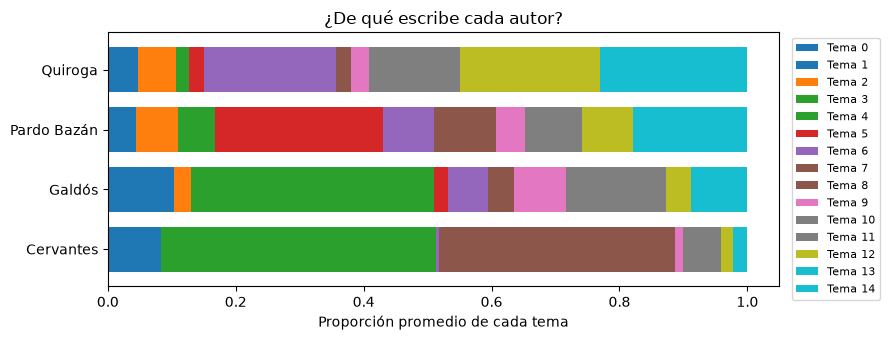

In [15]:
prop = pd.DataFrame(mezcla, columns=[f"Tema {k}" for k in range(N_TEMAS)]).groupby(autores).mean()
prop.plot(kind="barh", stacked=True, figsize=(9, 3.5), colormap="tab10", width=0.75)
plt.xlabel("Proporción promedio de cada tema"); plt.title("¿De qué escribe cada autor?")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

✏️ Cambia `N_TEMAS` a 4 y a 15. ¿Con cuántos temas el resultado tiene más sentido?

---
## Parte 5 · Atribución de autoría con TF-IDF y la trampa de los nombres propios

Entrenamos una regresión logística sobre TF-IDF con **validación cruzada de 5 particiones** y comparamos tres representaciones:
1. Solo palabras funcionales.
2. Todas las palabras.
3. Todas las palabras **menos los nombres propios**.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

FUNCIONALES = set('''de la que el en y a los se del las un por con no una su para es al lo como más pero sus le ya o
este sí porque esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos durante todos uno
les ni contra otros ese eso ante ellos e esto mí antes algunos qué unos yo otro otras otra él tanto esa estos mucho
quienes nada muchos cual poco ella estar estas algunas algo nosotros mi mis tú te ti tu tus ellas os cuanto aunque pues mientras'''.split())

# Nombres propios: palabras que en el texto original aparecen con mayúscula casi siempre
mayus = Counter(); total = Counter()
for t in textos.values():
    for w in re.findall(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+", t):
        total[w.lower()] += 1
        if w[0].isupper(): mayus[w.lower()] += 1
PROPIOS = {w for w, c in total.items() if c >= 5 and mayus[w] / c > 0.9}
print(f"{len(PROPIOS)} posibles nombres propios, por ejemplo: {sorted(PROPIOS)[:15]}")

def experimento(filtro):
    docs = [[t for t in d if filtro(t)] for d in fragmentos]
    modelo = make_pipeline(TfidfVectorizer(analyzer=lambda d: d, min_df=2), LogisticRegression(max_iter=2000))
    cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return cross_val_score(modelo, docs, autores, cv=cv5).mean()

resultados = {
    "Solo palabras funcionales": experimento(lambda t: t in FUNCIONALES),
    "Todas las palabras": experimento(lambda t: True),
    "Todas menos nombres propios": experimento(lambda t: t not in PROPIOS),
}
pd.Series(resultados, name="exactitud (5-fold)").map("{:.1%}".format)

331 posibles nombres propios, por ejemplo: ['adán', 'agi', 'agramante', 'ah', 'aldeacorba', 'aldonza', 'alejandro', 'alemania', 'alfonso', 'alicia', 'alonso', 'altisidora', 'alá', 'amadises', 'amadís']


Solo palabras funcionales      79.7%
Todas las palabras             98.8%
Todas menos nombres propios    95.9%
Name: exactitud (5-fold), dtype: str

---
## Parte 6 · Word2Vec: el significado sale del contexto

"Conocerás una palabra por la compañía que tiene" (Firth, 1957). **Word2Vec** (Mikolov et al., 2013) entrena una red pequeña para predecir las palabras vecinas; los pesos que aprende son los **vectores de las palabras**.

In [17]:
from gensim.models import Word2Vec

oraciones = [o for t in textos.values() for o in oraciones_de(t)]
print(f"{len(oraciones):,} oraciones, {sum(map(len, oraciones)):,} palabras")

w2v = Word2Vec(oraciones, vector_size=100, window=5, min_count=5, sg=1, epochs=10, workers=4, seed=42)
print("Vocabulario de Word2Vec:", len(w2v.wv), "palabras")

29,092 oraciones, 564,950 palabras
Vocabulario de Word2Vec: 8073 palabras


In [18]:
for w in ["caballero", "amor", "noche", "casa", "mujer", "dios", "ojos", "dinero"]:
    if w in w2v.wv:
        vecinos = ", ".join(f"{v} ({s:.2f})" for v, s in w2v.wv.most_similar(w, topn=6))
        print(f"{w:10s} → {vecinos}")

caballero  → andante (0.76), valeroso (0.66), vencido (0.66), príncipe (0.65), hidalgo (0.65), pierres (0.64)
amor       → proceder (0.66), imperio (0.66), codicia (0.65), origen (0.64), cuestión (0.64), tormento (0.64)
noche      → mañana (0.69), hora (0.67), última (0.67), tarde (0.67), comida (0.63), huyendo (0.63)
casa       → esclava (0.56), aldeacorba (0.56), recámara (0.55), cuarto (0.55), pazos (0.54), pueblo (0.54)
mujer      → marido (0.69), teresa (0.69), mari (0.66), sancha (0.65), muchacha (0.64), niña (0.63)
dios       → alá (0.59), parió (0.55), cielo (0.53), ayude (0.53), manda (0.53), amar (0.52)
ojos       → cerrados (0.62), fijos (0.61), suspiros (0.58), brazos (0.58), abiertos (0.57), propios (0.56)
dinero     → estorbo (0.78), desatino (0.76), pagaba (0.76), antojo (0.76), pulso (0.75), caletre (0.74)


In [19]:
def analogia(a, b, c, topn=5):
    # a es a b como c es a ...  →  b - a + c
    try:
        res = w2v.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
        print(f"{a} : {b} :: {c} : " + ", ".join(f"{w} ({s:.2f})" for w, s in res))
    except KeyError as e:
        print("Palabra fuera del vocabulario:", e)

analogia("hombre", "rey", "mujer")
analogia("padre", "hijo", "madre")
analogia("día", "sol", "noche")

hombre : rey :: mujer : patria (0.58), hacienda (0.55), dejé (0.55), case (0.54), carta (0.53)
padre : hijo :: madre : bendita (0.59), desdichada (0.58), estrella (0.57), santísima (0.56), puta (0.55)
día : sol :: noche : superficie (0.63), cerco (0.62), sed (0.62), claridad (0.61), atmósfera (0.60)


💬 Con un corpus de menos de un millón de palabras las analogías fallan seguido. Los ejemplos famosos (*rey − hombre + mujer ≈ reina*) usan miles de millones de palabras. ¿Qué nos dice eso sobre cuántos datos necesita un modelo para "entender"?

---
## Parte 7 · El mapa de las palabras

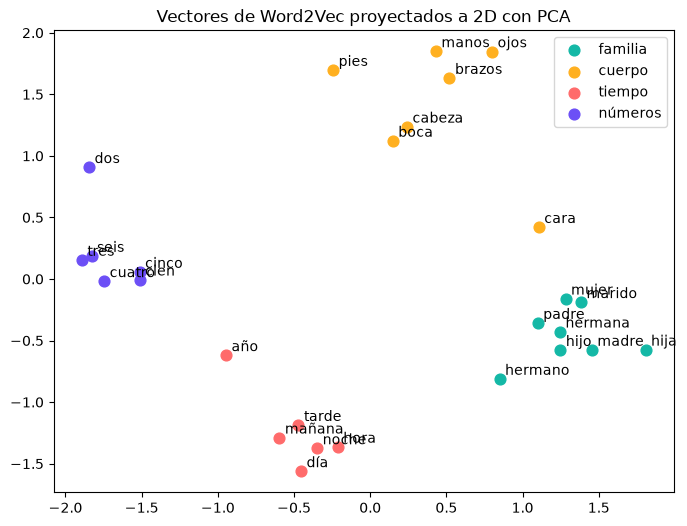

In [20]:
from sklearn.decomposition import PCA

grupos = {
    "familia": ["padre", "madre", "hijo", "hija", "hermano", "hermana", "marido", "mujer"],
    "cuerpo": ["ojos", "manos", "cabeza", "boca", "cara", "pies", "brazos"],
    "tiempo": ["día", "noche", "mañana", "tarde", "año", "hora"],
    "números": ["dos", "tres", "cuatro", "cinco", "seis", "cien"],
}
pal, col = [], []
for g, ws in grupos.items():
    for w in ws:
        if w in w2v.wv: pal.append(w); col.append(g)

P = PCA(n_components=2, random_state=42).fit_transform(np.array([w2v.wv[w] for w in pal]))
plt.figure(figsize=(8, 6))
for g, c in zip(grupos, ["#14B8A6", "#FFB020", "#FF6B6B", "#6C4FF6"]):
    m = np.array(col) == g
    plt.scatter(P[m, 0], P[m, 1], s=60, c=c, label=g)
for (x, y), w in zip(P, pal):
    plt.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=10)
plt.title("Vectores de Word2Vec proyectados a 2D con PCA"); plt.legend(); plt.show()

💬 ¿Las palabras de un mismo grupo quedan cerca? Esa cercanía la aprendió el modelo **solo de ver contextos**.

---
## Parte 8 · FastText: palabras que el modelo nunca vio

Word2Vec no tiene vector para una palabra que no estuvo en el entrenamiento: es el problema OOV. **FastText** (Bojanowski et al., 2017) representa cada palabra como la suma de sus **n-gramas de caracteres**, así que puede armar un vector para cualquier palabra.

In [21]:
from gensim.models import FastText

ft = FastText(oraciones, vector_size=100, window=5, min_count=5, sg=1, epochs=10, workers=4, seed=42, min_n=3, max_n=5)

def ngramas(w, n=3):
    w = f"<{w}>"
    return [w[i:i + n] for i in range(len(w) - n + 1)]
print("Trigramas de 'cantábamos':", ngramas("cantábamos"))

for w in ["googlear", "farmeamos", "cantaríamos", "quijotesco", "caballerosamente"]:
    en_w2v = w in w2v.wv
    vecinos = ", ".join(v for v, _ in ft.wv.most_similar(w, topn=5))
    print(f"{w:17s} ¿en Word2Vec? {'sí' if en_w2v else 'NO':3s} → vecinos en FastText: {vecinos}")

Trigramas de 'cantábamos': ['<ca', 'can', 'ant', 'ntá', 'táb', 'ába', 'bam', 'amo', 'mos', 'os>']
googlear          ¿en Word2Vec? NO  → vecinos en FastText: guiar, fiar, ejecutar, pelear, gozar
farmeamos         ¿en Word2Vec? NO  → vecinos en FastText: seamos, íbamos, veamos, hagamos, vengamos
cantaríamos       ¿en Word2Vec? NO  → vecinos en FastText: dijésemos, digamos, éramos, íbamos, seamos
quijotesco        ¿en Word2Vec? NO  → vecinos en FastText: quijote, quijano, dote, escote, galeote
caballerosamente  ¿en Word2Vec? NO  → vecinos en FastText: caballeriza, caballero, cabal, caballeros, caballería


💬 ¿Los vecinos que propone FastText para palabras inventadas tienen sentido? ¿Se parecen por significado o solo por **forma**?

---
## Parte 9 · BPE desde cero

**Byte-Pair Encoding** (Sennrich, Haddow y Birch, 2016) construye un vocabulario de pedazos de palabra: empieza con caracteres y fusiona una y otra vez el par de símbolos vecinos más frecuente. Es lo que usan GPT y la mayoría de los modelos actuales.

In [24]:
def aprender_bpe(frecuencias, n_fusiones=300):
    vocab = {tuple(w) + ("</w>",): f for w, f in frecuencias.items()}
    fusiones = []
    for _ in range(n_fusiones):
        pares = Counter()
        for simbolos, f in vocab.items():
            for par in zip(simbolos, simbolos[1:]):
                pares[par] += f
        if not pares:
            break
        mejor = max(pares, key=pares.get)
        fusiones.append(mejor)
        nuevo = {}
        for simbolos, f in vocab.items():
            s, i = [], 0
            while i < len(simbolos):
                if i < len(simbolos) - 1 and (simbolos[i], simbolos[i + 1]) == mejor:
                    s.append(simbolos[i] + simbolos[i + 1]); i += 2
                else:
                    s.append(simbolos[i]); i += 1
            nuevo[tuple(s)] = f
        vocab = nuevo
    return fusiones

def aplicar_bpe(palabra, fusiones):
    s = list(palabra) + ["</w>"]
    for a, b in fusiones:
        i, t = 0, []
        while i < len(s):
            if i < len(s) - 1 and s[i] == a and s[i + 1] == b:
                t.append(a + b); i += 2
            else:
                t.append(s[i]); i += 1
        s = t
    return s

frec = Counter(t for toks in tokens.values() for t in toks)
fusiones = aprender_bpe(dict(frec.most_common(5000)), n_fusiones=2000)
print("Primeras 15 fusiones:", ["".join(p) for p in fusiones[:15]])
for w in ["cantábamos", "dámelo", "farmeamos", "calle", "desafortunadamente", "googlear"]:
    print(f"{w:20s} → {' · '.join(aplicar_bpe(w, fusiones))}")

Primeras 15 fusiones: ['e</w>', 'a</w>', 'o</w>', 's</w>', 'n</w>', 'qu', 'er', 'de</w>', 'que</w>', 'y</w>', 'l</w>', 'os</w>', 'en', 'es', 'la</w>']
cantábamos           → cant · á · b · amos</w>
dámelo               → d · á · me · lo</w>
farmeamos            → f · ar · me · amos</w>
calle                → cal · le</w>
desafortunadamente   → des · a · fort · un · ad · amente</w>
googlear             → go · o · g · le · ar</w>


💬 ¿Los cortes coinciden con los morfemas? BPE corta por **frecuencia**, no por gramática: a veces acierta (*-mos*, *-mente*) y a veces no.

✏️ Cambia `n_fusiones` a 50 y a 2000. ¿Qué pasa con el número de piezas por palabra?

---
## Parte 10 · La red social del Quijote

Si dos personajes aparecen cerca en el texto, probablemente interactúan. Contamos cuántas veces aparecen juntos en ventanas de 50 palabras y dibujamos la red.

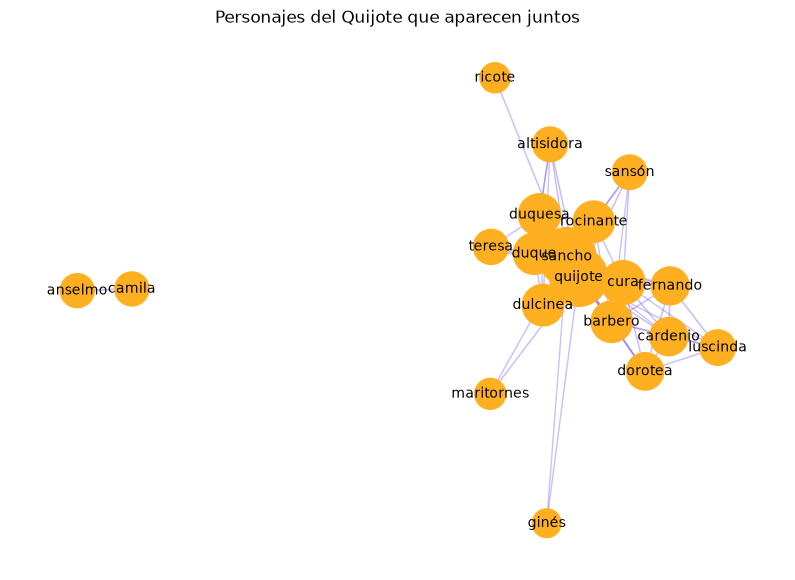

quijote     0.84
sancho      0.84
cura        0.53
barbero     0.47
fernando    0.42
cardenio    0.37
dorotea     0.37
duque       0.32
dtype: float64


In [25]:
import networkx as nx

PERSONAJES = ["quijote", "sancho", "dulcinea", "rocinante", "cura", "barbero", "teresa", "sansón", "duque", "duquesa",
              "cardenio", "dorotea", "luscinda", "fernando", "maritornes", "ginés", "altisidora", "ricote", "camila", "anselmo"]
toks_q = tokens["Cervantes"]
VENTANA = 50
co = Counter()
for i in range(0, len(toks_q), VENTANA):
    presentes = sorted(set(toks_q[i:i + VENTANA]) & set(PERSONAJES))
    for a in range(len(presentes)):
        for b in range(a + 1, len(presentes)):
            co[(presentes[a], presentes[b])] += 1

G = nx.Graph()
for (a, b), c in co.items():
    if c >= 3: G.add_edge(a, b, weight=c)

if G.number_of_nodes() > 1:
    pos = nx.spring_layout(G, seed=4, k=0.9)
    pesos = np.array([G[u][v]["weight"] for u, v in G.edges()])
    plt.figure(figsize=(10, 7))
    nx.draw_networkx_edges(G, pos, width=1 + 6 * pesos / pesos.max(), alpha=0.35, edge_color="#6C4FF6")
    tam = [300 + 40 * G.degree(n, weight="weight") ** 0.5 for n in G.nodes()]
    nx.draw_networkx_nodes(G, pos, node_size=tam, node_color="#FFB020")
    nx.draw_networkx_labels(G, pos, font_size=10)
    plt.axis("off"); plt.title("Personajes del Quijote que aparecen juntos"); plt.show()
    print(pd.Series(nx.degree_centrality(G)).sort_values(ascending=False).head(8).round(2))
else:
    print("No se encontraron suficientes personajes en el texto.")